In [1]:
# First step import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
print("Lets Goooo!")

Lets Goooo!


In [2]:
from getpass import getpass
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# A box will appear at the top of VS Code asking for your password. Type it and press Enter.
password = getpass("PostgreSQL password: ")

url = URL.create(
    "postgresql+psycopg2",
    username="postgres",
    password=password,
    host="localhost",
    port=5432,
    database="yelp_project",
)
engine = create_engine(url)

# Ask the database one simple question to prove the connection works
with engine.connect() as conn:
    rows = conn.execute(text("SELECT COUNT(*) FROM clean.reviews")).scalar()
print("Connected. Reviews in clean.reviews:", rows)

Connected. Reviews in clean.reviews: 307510


In [3]:
import sys
print(sys.executable)

C:\Users\DELL PC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


In [4]:
# CHECKING THE CONNECTION AND IMPORTING LIBRARIES


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

# --- connect to the database (the password is never saved in the file) ---
password = getpass("PostgreSQL password: ")
engine = create_engine(URL.create(
    "postgresql+psycopg2", username="postgres", password=password,
    host="localhost", port=5432, database="yelp_project"))

# --- load the four clean tables (the reviews table takes 10-30 seconds) ---
business   = pd.read_sql("SELECT * FROM clean.business", engine)
users      = pd.read_sql("SELECT * FROM clean.users", engine)
reviews    = pd.read_sql("SELECT * FROM clean.reviews", engine)
categories = pd.read_sql("SELECT * FROM clean.business_categories", engine)

# --- check the shapes: (rows, columns) ---
print("business  ", business.shape)
print("users     ", users.shape)
print("reviews   ", reviews.shape)
print("categories", categories.shape)

business   (52263, 13)
users      (214971, 8)
reviews    (307510, 17)
categories (243587, 2)


In [5]:
# What we’re doing: before making any chart, check the column types, count the missing values,
#  and read the summary numbers. This is the Python version of the profiling you did in SQL, 
# and it also confirms nothing changed on the way in.


# --- 1) column names and types of the reviews table
print(reviews.dtypes)

# --- 2) missing values, as COUNTS (a percentage would round tiny numbers to 0)
for name, df in [("business", business), ("users", users), ("reviews", reviews) , ("categories", categories)]:
    miss = df.isna().sum()
    print(f"{name}: missing ->", miss[miss > 0].to_dict() or "none")

# --- 3) summary of the number columns
print(reviews[["stars", "text_length", "useful_votes"]].describe().round(2))
print(business[["business_stars", "total_reviews_all_time"]].describe().round(2))


review_id                  object
user_id                    object
business_id                object
stars                       int64
star_group                 object
review_datetime    datetime64[ns]
review_date                object
review_year                 int64
review_month                int64
is_partial_year             int64
useful_votes                int64
funny_votes                 int64
cool_votes                  int64
review_text                object
text_length                 int64
is_short_review             int64
has_url                     int64
dtype: object
business: missing -> {'postal_code': 21}
users: missing -> {'total_reviews_all_time': 2}
reviews: missing -> none
categories: missing -> none
           stars  text_length  useful_votes
count  307510.00    307510.00     307510.00
mean        3.79       544.41          0.98
std         1.39       502.66          2.58
min         1.00         1.00          0.00
25%         3.00       218.00          0.00
50

stars
1    12.0
2     8.6
3    11.5
4    23.9
5    44.0
Name: proportion, dtype: float64


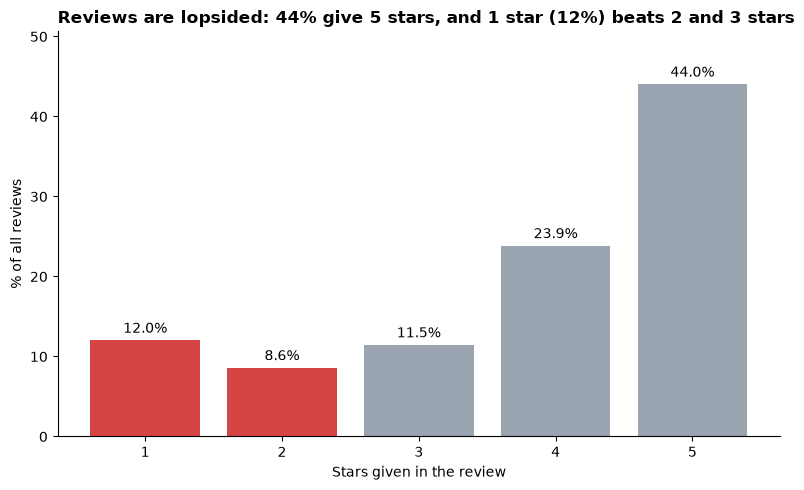

negative share (1-2 stars): 20.6 %


In [ ]:
# What we’re doing: 
# before comparing states or years, we need to know what a normal review looks like. 
# This is the baseline everything else gets measured against.

# THIS TABLE SHOWS THE PERCENTAGE OF REVIEWS THAT GIVE EACH STAR RATING, 
# AND IT ALSO SHOWS THE PERCENTAGE OF REVIEWS THAT ARE NEGATIVE (1 OR 2 STARS).


# 1) what share of all reviews gives each star rating?
share = reviews["stars"].value_counts(normalize=True).sort_index() * 100
print(share.round(1))

# 2) draw it: red = negative (1-2 stars), grey = everything else
colors = ["#D64545" if s <= 2 else "#9AA5B1" for s in share.index]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(share.index, share.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Stars given in the review")
ax.set_ylabel("% of all reviews")
ax.set_title(f"Reviews are lopsided: {share[5]:.0f}% give 5 stars, and 1 star ({share[1]:.0f}%) beats 2 and 3 stars",
             loc="left", fontsize=12, fontweight="bold")
ax.set_ylim(0, share.max() * 1.15)
sns.despine()
plt.tight_layout()
plt.show()

print("negative share (1-2 stars):", round(share[[1, 2]].sum(), 1), "%")

rows before the join: 307510 | after: 307510
       reviews  pct_negative
state                       
IL        2362          27.3
DE        3228          25.4
NJ       11110          24.7
NV       15888          22.9
AZ       17110          22.8
AB        4531          21.5
ID        6756          21.0
FL       51398          20.8
PA       71967          20.7
MO       23100          20.7
TN       28229          20.3
IN       21952          19.7
LA       36180          18.2
CA       13699          17.3

baseline (all reviews): 20.6% negative


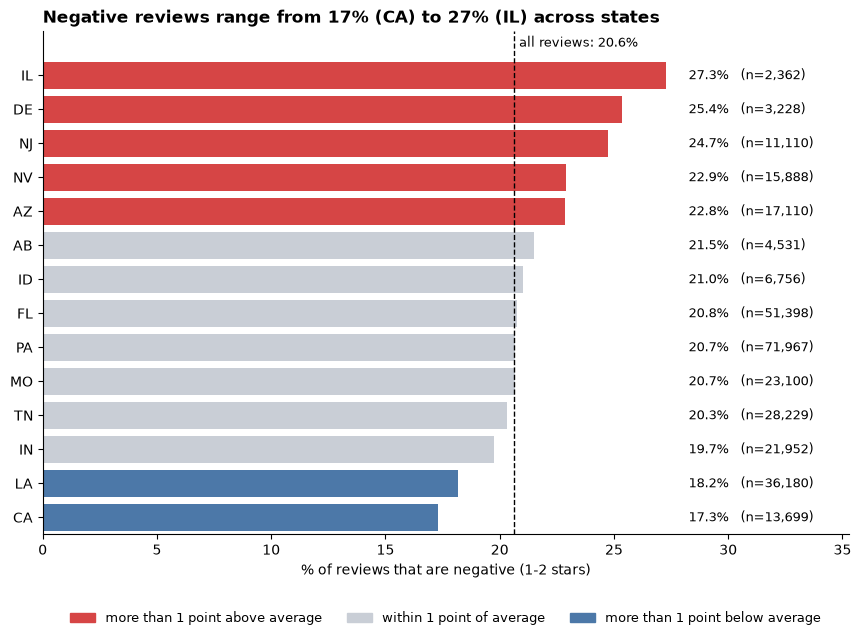

In [7]:
# WHICH STATES HAVE THE MOST NEGATIVE/UNHAPPY REVIEWS? (1 OR 2 STARS)

from matplotlib.patches import Patch

# 1) attach each review's state (a join). The row counts before and after must match.
before = len(reviews)
rev = reviews.merge(business[["business_id", "state", "country"]], on="business_id", how="left")
print("rows before the join:", before, "| after:", len(rev))

# 2) for each state: how many reviews, and what % of them are negative (1-2 stars)?
rev["is_negative"] = (rev["star_group"] == "negative")
by_state = (rev.groupby("state")
               .agg(reviews=("review_id", "count"), pct_negative=("is_negative", "mean"))
               .assign(pct_negative=lambda d: d["pct_negative"] * 100)
               .sort_values("pct_negative", ascending=False))
baseline = rev["is_negative"].mean() * 100
print(by_state.round(1))
print(f"\nbaseline (all reviews): {baseline:.1f}% negative")

# 3) draw it. Colour only the states that are clearly different from the baseline (more than 1 point away)
def pick_color(p):
    if p > baseline + 1: return "#D64545"      # clearly worse than average
    if p < baseline - 1: return "#4C78A8"      # clearly better than average
    return "#C9CED6"                           # about the same as average
colors = [pick_color(p) for p in by_state["pct_negative"]]

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(by_state.index, by_state["pct_negative"], color=colors)
ax.invert_yaxis()                                   # highest at the top
ax.axvline(baseline, color="black", linestyle="--", linewidth=1)
ax.text(baseline + 0.2, -0.75, f"all reviews: {baseline:.1f}%", fontsize=9, va="bottom")
label_x = by_state["pct_negative"].max() + 1.0       # labels sit in one column on the right
for bar, n in zip(bars, by_state["reviews"]):
    ax.text(label_x, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%   (n={n:,})", va="center", fontsize=9)
ax.set_xlabel("% of reviews that are negative (1-2 stars)")
ax.set_xlim(0, label_x + 7)
ax.set_ylim(len(by_state) - 0.5, -1.3)
top, low = by_state.index[0], by_state.index[-1]
ax.set_title(f"Negative reviews range from {by_state['pct_negative'].min():.0f}% ({low}) to {by_state['pct_negative'].max():.0f}% ({top}) across states",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#D64545", label="more than 1 point above average"),
                   Patch(color="#C9CED6", label="within 1 point of average"),
                   Patch(color="#4C78A8", label="more than 1 point below average")],
          loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

HOW TO READ THE CHART -

The bars are states ... the lenght shows the percentage of how bad the reviews are (1 or 2 stars)

The dashed line shows the share of ALL reviews that are negative (1 to 2 stars): 20.6%, or about 1 in 5.
Each bar shows the same share for one state. A bar that reaches past the line means that state
has a higher share of negative reviews than the overall average. A shorter bar means a lower share.
Red marks states clearly above average, and blue marks states clearly below.

n - number of reveiws the state has

rows before the join: 307510 | after: 307510
cities in the data: 771 | cities with at least 2000 reviews: 17
                      reviews  restaurants  pct_negative  margin
place                                                           
Sparks, NV               2614          282          27.9     1.7
Metairie, LA             2831          436          24.1     1.6
Wilmington, DE           2070          456          23.8     1.8
Franklin, TN             2525          373          23.3     1.6
Tucson, AZ              16019         1986          22.5     0.6
Reno, NV                13089         1124          21.9     0.7
Edmonton, AB             4222         1442          21.4     1.2
Clearwater, FL           3652          544          20.4     1.3
Tampa, FL               19642         2341          20.0     0.6
Boise, ID                4490          678          19.1     1.1
Indianapolis, IN        16330         2259          18.7     0.6
Saint Petersburg, FL     7012          843    

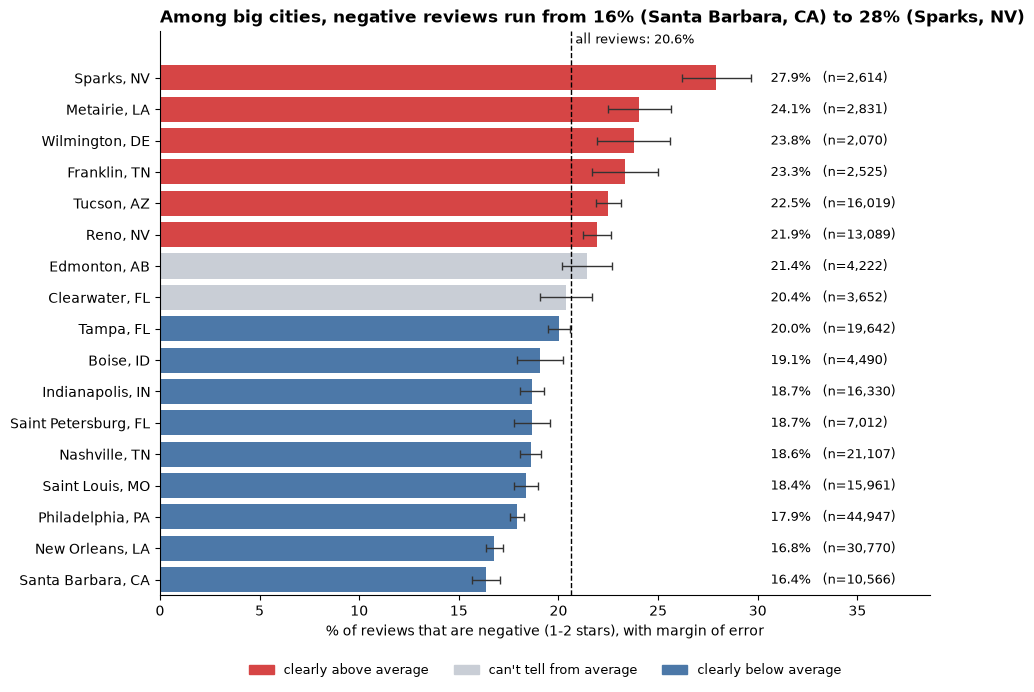

In [ ]:
# WHICH BIG CITIES HAVE THE MOST NEGATIVE REVIEWS?

# What we’re doing: 
# comparing cities by their rate of negative reviews, 
# as we did with states. Cities vary a lot in size, so this time we add a margin of error: 
# how far the true rate could be from what we measured, because we only have a sample. 
# We hide cities with fewer than 2,000 reviews, which leaves 17. (check the SQL version for the full list of cities and their review counts)


import numpy as np     # don't need to do this again but it makes the code clearer
from matplotlib.patches import Patch        # draw a legend with coloured boxes

MIN_REVIEWS = 2000          # only compare cities with at least this many reviews (you can change it)

# 1) attach city and state to every review (check the row count again)
before = len(reviews)
rev = reviews.merge(business[["business_id", "city", "state"]], on="business_id", how="left")
print("rows before the join:", before, "| after:", len(rev))   # just to check if adding the city and state changed the row count (it shouldn't)
rev["place"] = rev["city"] + ", " + rev["state"]        # two cities can share a name in different states....so we add the state and the city together 
rev["is_negative"] = (rev["star_group"] == "negative")
baseline = rev["is_negative"].mean() * 100

# 2) per city: reviews, restaurants, % negative, and the margin of error
by_city = (rev.groupby("place")
              .agg(reviews=("review_id", "count"),
                   restaurants=("business_id", "nunique"),
                   p=("is_negative", "mean")))
by_city["pct_negative"] = by_city["p"] * 100
by_city["margin"] = 1.96 * np.sqrt(by_city["p"] * (1 - by_city["p"]) / by_city["reviews"]) * 100
print("cities in the data:", len(by_city), "| cities with at least", MIN_REVIEWS, "reviews:", (by_city["reviews"] >= MIN_REVIEWS).sum())

big = by_city[by_city["reviews"] >= MIN_REVIEWS].sort_values("pct_negative", ascending=False)
print(big[["reviews", "restaurants", "pct_negative", "margin"]].round(1))

# 3) colour: red only if the WHOLE range (bar +/- margin) is above the baseline, blue if wholly below
def pick_color(row):
    if row["pct_negative"] - row["margin"] > baseline: return "#D64545"
    if row["pct_negative"] + row["margin"] < baseline: return "#4C78A8"
    return "#C9CED6"
colors = big.apply(pick_color, axis=1)

fig, ax = plt.subplots(figsize=(9.5, 7))
bars = ax.barh(big.index, big["pct_negative"], xerr=big["margin"], color=colors,
               error_kw=dict(ecolor="#333333", capsize=3, lw=1))
ax.invert_yaxis()
ax.axvline(baseline, color="black", linestyle="--", linewidth=1)
ax.text(baseline + 0.2, -1.0, f"all reviews: {baseline:.1f}%", fontsize=9, va="bottom")
label_x = (big["pct_negative"] + big["margin"]).max() + 1.0
for y, (pct, n) in enumerate(zip(big["pct_negative"], big["reviews"])):
    ax.text(label_x, y, f"{pct:.1f}%   (n={n:,})", va="center", fontsize=9)
ax.set_xlabel("% of reviews that are negative (1-2 stars), with margin of error")
ax.set_xlim(0, label_x + 8)
ax.set_ylim(len(big) - 0.5, -1.5)
hi, lo = big.index[0], big.index[-1]
ax.set_title(f"Among big cities, negative reviews run from {big['pct_negative'].min():.0f}% ({lo}) to {big['pct_negative'].max():.0f}% ({hi})",
             loc="left", fontsize=12, fontweight="bold")
ax.legend(handles=[Patch(color="#D64545", label="clearly above average"),
                   Patch(color="#C9CED6", label="can't tell from average"),
                   Patch(color="#4C78A8", label="clearly below average")],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()



HOW TO READ THE MARGIN OF ERROR LINES BAR CHART 

Each bar has a thin line through its end. That line is the margin of error, the range the true rate probably falls in. A bar is coloured only if its whole range is on one side of the dashed line. Edmonton and Clearwater are grey because their whiskers cross the line, so we can’t tell them from average. Tampa is borderline, because its whisker just touches the line, so read it as roughly average. This is also why small cities have longer whiskers: less data means less certainty.


MAJOR INSIGHT 

(1) Cities differ even inside one state. Louisiana’s state rate was 18.2%, but Metairie is 24.1% and New Orleans is 16.8%, a gap of over 7 points. In Nevada, Sparks is 27.9% and Reno is 21.9%. The state number hides these differences, which is why we compare cities.


(2) The big city centres are on the happy side. Philadelphia, New Orleans, Nashville and Santa Barbara all come out clearly below average. Some nearby smaller cities (Metairie, Sparks, Franklin) come out above it. That’s a pattern worth checking later, not a finding yet, because the data can’t tell us why.

QUESTION?

Louisiana’s state average hides the gap between Metairie and New Orleans. In one sentence, why is it risky to give a restaurant owner only the state-level number?

ANSWER 

A state average blends cities that behave very differently, so it can hide that a local owner’s customers are much happier or unhappier than the state figure suggests

LESSON CONCLUSION 

The more you average together, the more you hide. Always check whether a headline number looks the same inside its groups. That’s why we’ll compare cities, and then cuisines, before drawing conclusions.